In [4]:
# Step 1: Import libraries and load the dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset 
df = pd.read_csv("lead_conversion_dataset.csv")

# Display the first 5 rows
df.head()

,Age,Income,Website_Visits,Calls,Previous_Purchase,Converted
0,59,88182,6,1,No,No
1,49,32801,8,3,Yes,Yes
2,35,127881,6,5,Yes,Yes
3,63,109431,7,1,No,No
4,28,69749,9,2,Yes,No


In [5]:
# Step 2: Explore the dataset

# 1) Shape of the dataset (rows, columns)
print("Dataset shape:", df.shape)

# 2) Data types and non-null counts
print("\n--- Data Info ---")
df.info()

# 3) Missing values per column
print("\n--- Missing Values ---")
print(df.isnull().sum())

# 4) Summary statistics for numeric columns
print("\n--- Summary Statistics ---")
df.describe()

Dataset shape: (10000, 6)

--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Age                10000 non-null  int64 
 1   Income             10000 non-null  int64 
 2   Website_Visits     10000 non-null  int64 
 3   Calls              10000 non-null  int64 
 4   Previous_Purchase  10000 non-null  object
 5   Converted          10000 non-null  object
dtypes: int64(4), object(2)
memory usage: 468.9+ KB

--- Missing Values ---
Age                  0
Income               0
Website_Visits       0
Calls                0
Previous_Purchase    0
Converted            0
dtype: int64

--- Summary Statistics ---


,Age,Income,Website_Visits,Calls
count,10000.000000,10000.000000,10000.000000,10000.000000
mean,43.038200,89315.786200,7.023200,1.979400
std,12.895611,34742.985118,2.468131,1.397201
min,21.000000,30005.000000,1.000000,0.000000
25%,32.000000,58390.750000,5.000000,1.000000
50%,43.000000,89330.500000,7.000000,2.000000
75%,54.000000,119124.750000,9.000000,3.000000
max,65.000000,149988.000000,18.000000,12.000000


In [6]:
# 5) Class balance — how many Yes vs No in target column
print("Target distribution:")
print(df['Converted'].value_counts())

print("\nPercentage:")
print(df['Converted'].value_counts(normalize=True) * 100)

Target distribution:
Converted
No     5519
Yes    4481
Name: count, dtype: int64

Percentage:
Converted
No     55.19
Yes    44.81
Name: proportion, dtype: float64


In [7]:
# Step 3: Encode categorical columns (Yes/No → 1/0)

# Make a copy so we keep the original dataframe safe
df_encoded = df.copy()

# Convert Previous_Purchase: Yes → 1, No → 0
df_encoded['Previous_Purchase'] = df_encoded['Previous_Purchase'].map({'Yes': 1, 'No': 0})

# Convert Converted (target): Yes → 1, No → 0
df_encoded['Converted'] = df_encoded['Converted'].map({'Yes': 1, 'No': 0})

# Check the result
print("First 5 rows after encoding:")
print(df_encoded.head())

print("\nData types after encoding:")
print(df_encoded.dtypes)

First 5 rows after encoding:
   Age  Income  Website_Visits  Calls  Previous_Purchase  Converted
0   59   88182               6      1                  0          0
1   49   32801               8      3                  1          1
2   35  127881               6      5                  1          1
3   63  109431               7      1                  0          0
4   28   69749               9      2                  1          0

Data types after encoding:
Age                  int64
Income               int64
Website_Visits       int64
Calls                int64
Previous_Purchase    int64
Converted            int64
dtype: object


In [8]:
# Step 4: Split data into Training and Testing sets

from sklearn.model_selection import train_test_split

# Separate features (X) from target (y)
X = df_encoded.drop('Converted', axis=1)  # everything except the target
y = df_encoded['Converted']               # the target column

# Split: 80% training, 20% testing
# random_state=42 makes the split reproducible
# stratify=y keeps the Yes/No ratio balanced in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check the sizes
print("Training set size:", X_train.shape)
print("Testing set size :", X_test.shape)

print("\nTarget distribution in TRAINING set:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTarget distribution in TESTING set:")
print(y_test.value_counts(normalize=True) * 100)

Training set size: (8000, 5)
Testing set size : (2000, 5)

Target distribution in TRAINING set:
Converted
0    55.1875
1    44.8125
Name: proportion, dtype: float64

Target distribution in TESTING set:
Converted
0    55.2
1    44.8
Name: proportion, dtype: float64


In [9]:
# Step 5: Train a Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

# Create the model
# n_estimators=100 → 100 decision trees in the forest
# random_state=42 → reproducible results
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model on the training data
model.fit(X_train, y_train)

print("Model trained successfully!")
print("\nModel details:")
print(model)

Model trained successfully!

Model details:
RandomForestClassifier(random_state=42)


In [10]:
# Step 6: Evaluate the model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Calculate the main metrics
accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall    = recall_score(y_test, y_pred)
f1        = f1_score(y_test, y_pred)

# Print the metrics
print("=" * 50)
print("MODEL EVALUATION RESULTS")
print("=" * 50)
print(f"Accuracy : {accuracy:.4f}  ({accuracy*100:.2f}%)")
print(f"Precision: {precision:.4f}  ({precision*100:.2f}%)")
print(f"Recall   : {recall:.4f}  ({recall*100:.2f}%)")
print(f"F1 Score : {f1:.4f}  ({f1*100:.2f}%)")
print("=" * 50)

# Confusion Matrix
print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)

# Full classification report
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred, target_names=['No', 'Yes']))

MODEL EVALUATION RESULTS
Accuracy : 0.6045  (60.45%)
Precision: 0.5639  (56.39%)
Recall   : 0.5167  (51.67%)
F1 Score : 0.5393  (53.93%)

Confusion Matrix:
[[746 358]
 [433 463]]

Detailed Classification Report:
              precision    recall  f1-score   support

          No       0.63      0.68      0.65      1104
         Yes       0.56      0.52      0.54       896

    accuracy                           0.60      2000
   macro avg       0.60      0.60      0.60      2000
weighted avg       0.60      0.60      0.60      2000



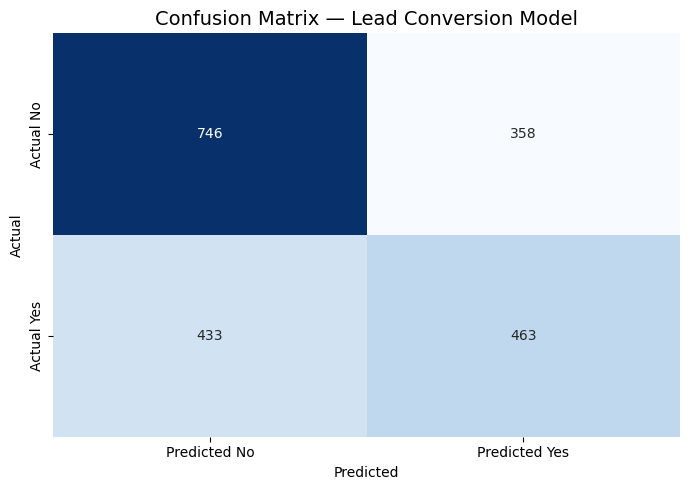

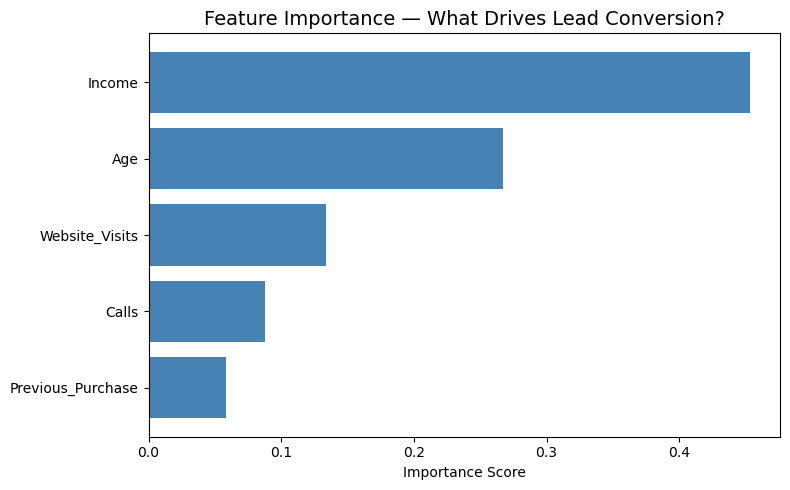


Feature Importance Ranking:
          Feature  Importance
           Income    0.453244
              Age    0.266847
   Website_Visits    0.133390
            Calls    0.088091
Previous_Purchase    0.058428


In [11]:
# Step 7: Visualizations

# ---- Plot 1: Confusion Matrix Heatmap ----
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Predicted No', 'Predicted Yes'],
    yticklabels=['Actual No', 'Actual Yes'],
    cbar=False
)
plt.title('Confusion Matrix — Lead Conversion Model', fontsize=14)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

# ---- Plot 2: Feature Importance ----
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
}).sort_values('Importance', ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(feature_importance['Feature'], feature_importance['Importance'], color='steelblue')
plt.title('Feature Importance — What Drives Lead Conversion?', fontsize=14)
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

# Print the values too
print("\nFeature Importance Ranking:")
print(feature_importance.sort_values('Importance', ascending=False).to_string(index=False))

# Business Interpretation & Deployment Recommendation

## 1. Model Performance Summary

| Metric    | Score   | What It Means |
|-----------|---------|---------------|
| Accuracy  | 60.45%  | Out of every 100 leads, the model classifies 60 correctly |
| Precision | 56.39%  | When model says "will convert", it is right 56% of the time |
| Recall    | 51.67%  | Model identifies only 52% of leads who actually convert |
| F1 Score  | 53.93%  | Balance between Precision and Recall is moderate |

**Baseline comparison:** If we predicted "No" for every lead, we would already be 55% accurate. Our model is only 5 percentage points better than this naive baseline.

## 2. Confusion Matrix Interpretation

Out of 2,000 leads in the test set:
- **746 True Negatives** — correctly identified leads who would not convert
- **463 True Positives** — correctly identified leads who would convert
- **358 False Positives** — sales effort wasted on leads who will not buy
- **433 False Negatives** — real opportunities missed by the model

The 433 missed opportunities (False Negatives) are particularly costly for a sales-driven business — these are real buyers the model fails to flag.

## 3. Key Drivers of Lead Conversion

The Feature Importance ranking reveals what actually drives conversion in this dataset:

| Rank | Feature           | Importance |
|------|-------------------|------------|
| 1    | Income            | 45.3%      |
| 2    | Age               | 26.7%      |
| 3    | Website Visits    | 13.3%      |
| 4    | Calls             | 8.8%       |
| 5    | Previous Purchase | 5.8%       |

**Business insight:** Income and Age together explain 72% of the prediction power. Surprisingly, prior purchase history contributes the least — suggesting that in this market, demographic factors outweigh customer loyalty signals.

## 4. Deployment Recommendation: NOT READY FOR PRODUCTION

I do not recommend deploying this model in its current form for the following reasons:

1. **Marginal lift over baseline** — only 5% better than a "predict everyone says No" rule
2. **Low Recall (52%)** — the model misses nearly half of real converting leads, which directly translates to lost revenue
3. **Weak F1 score (54%)** — neither precision nor recall is strong enough to drive confident business decisions

## 5. Next Steps to Improve the Model

1. **Collect richer data** — add fields such as lead source, time on site, email engagement, product interest category, and geographic region
2. **Try other algorithms** — test Gradient Boosting (XGBoost or LightGBM) which often outperforms Random Forest on tabular data
3. **Tune hyperparameters** — use Grid Search or Random Search to optimize the Random Forest settings
4. **Engineer new features** — create combinations such as Income-per-Age, or interaction terms between Calls and Website Visits
5. **Rebalance training approach** — apply techniques like SMOTE or class weights if class imbalance is found
6. **Re-evaluate with new data** — once improvements are made, re-run the full evaluation pipeline before any deployment decision

## 6. Conclusion

The current model demonstrates a working end-to-end machine learning pipeline, but its predictive power is too weak for production use. With richer features and a more advanced algorithm, performance can likely be improved significantly. I recommend an iteration cycle of feature collection and model retraining before reconsidering deployment.